## Customer Analytics

In [49]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# Thiết lập thư mục và đọc dữ liệu
data_path = Path("data/raw/Dunnhumby/transaction_data.csv")
if not data_path.exists():
    data_path = Path("../data/raw/Dunnhumby/transaction_data.csv")

print(f"Đang đọc dữ liệu từ: {data_path}")
df_raw = pd.read_csv(data_path, usecols=["household_key", "BASKET_ID", "DAY", "SALES_VALUE"])
print(f"Tổng số dòng giao dịch thô: {len(df_raw):,}")

Đang đọc dữ liệu từ: ..\data\raw\Dunnhumby\transaction_data.csv
Tổng số dòng giao dịch thô: 2,595,732


In [50]:
# Lọc giao dịch hợp lệ (SALES_VALUE > 0) và trích xuất các ngày mua sắm duy nhất theo hộ gia đình
df_valid = (
    df_raw[df_raw["SALES_VALUE"] > 0][["household_key", "DAY"]]
    .drop_duplicates()
    .sort_values(["household_key", "DAY"])
)

# Tính khoảng cách số ngày giữa các lần ghé mua liên tiếp (Return Gap in Days)
df_valid["gap_days"] = df_valid.groupby("household_key")["DAY"].diff()
gaps = df_valid["gap_days"].dropna().astype(int)

print(f"Tổng số lượt quay lại mua sắm (Return events): {len(gaps):,}")
print(f"Số hộ gia đình phát sinh >= 2 lần mua: {df_valid['household_key'].nunique():,}")

Tổng số lượt quay lại mua sắm (Return events): 222,785
Số hộ gia đình phát sinh >= 2 lần mua: 2,500


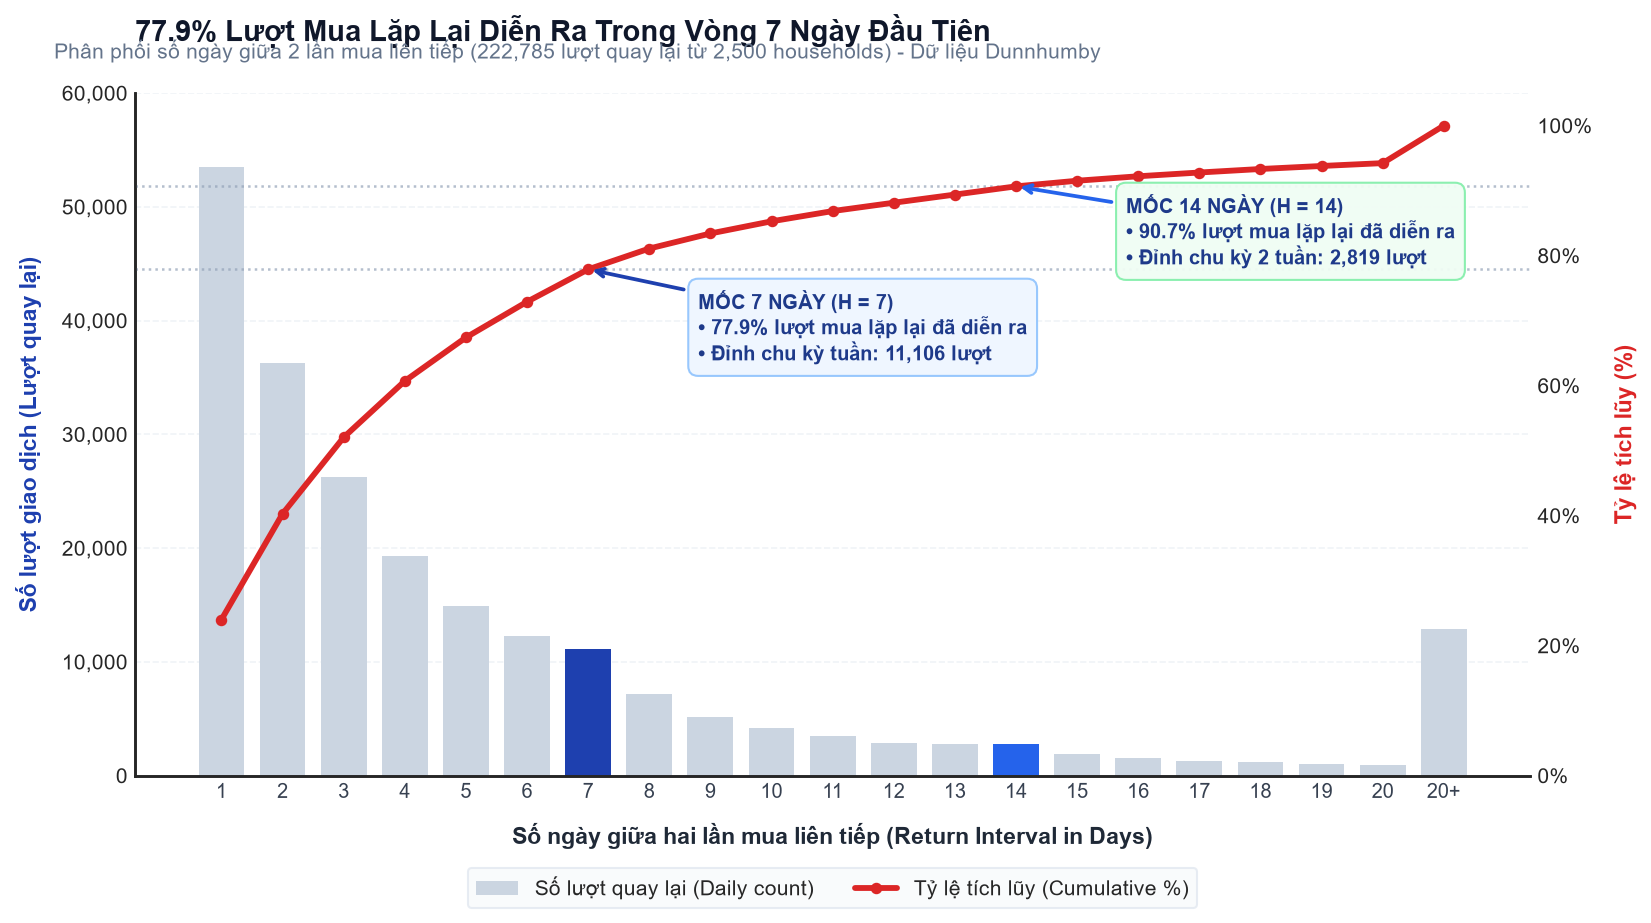

In [ ]:
# Gom nhóm phân phối từ 1 đến 20 ngày và nhóm '20+'
counts = {}
for i in range(1, 21):
    counts[str(i)] = (gaps == i).sum()

df_plot = pd.DataFrame(list(counts.items()), columns=["day", "count"])
total = len(gaps)
df_plot["pct"] = df_plot["count"] / total * 100
df_plot["cum_pct"] = df_plot["count"].cumsum() / total * 100

# VẼ BIỂU ĐỒ KẾT HỢP (COMBO BAR CHART + CUMULATIVE PERCENTAGE LINE)
plt.style.use("seaborn-v0_8-white" if "seaborn-v0_8-white" in plt.style.available else "default")
fig, ax1 = plt.subplots(figsize=(12, 6.5), dpi=150)

x = np.arange(len(df_plot))

# Màu sắc cột: Tô đậm nổi bật Ngày 7, Ngày 14
colors = []
for d in df_plot["day"]:
    if d == "7":
        colors.append("#1E40AF")  # Xanh navy đậm cho Ngày 7
    elif d == "14":
        colors.append("#2563EB")  # Xanh royal cho Ngày 14
    else:
        colors.append("#CBD5E1")  # Xám nhạt cho các ngày thường

# Trục trái: Cột tần suất số lượt quay lại từng ngày
bars = ax1.bar(x, df_plot["count"], color=colors, width=0.75, label="Số lượt quay lại (Daily count)", zorder=2)
ax1.set_xlabel("Số ngày giữa hai lần mua liên tiếp (Return Interval in Days)", fontsize=11, fontweight="bold", labelpad=10, color="#1F2937")
ax1.set_ylabel("Số lượt giao dịch (Lượt quay lại)", fontsize=11, fontweight="bold", color="#1E40AF", labelpad=10)
ax1.set_xticks(x)
ax1.set_xticklabels(df_plot["day"], fontsize=9.5, color="#374151")
ax1.yaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))
ax1.set_ylim(0, 60000)
ax1.grid(axis="y", linestyle="--", alpha=0.5, color="#E2E8F0", zorder=1)

# Trục phải: Đường cong tỷ lệ tích lũy %
ax2 = ax1.twinx()
line = ax2.plot(x, df_plot["cum_pct"], color="#DC2626", linewidth=2.8, marker="o", markersize=4.5,
                label="Tỷ lệ tích lũy (Cumulative %)", zorder=4)
ax2.set_ylabel("Tỷ lệ tích lũy (%)", fontsize=11, fontweight="bold", color="#DC2626", labelpad=10)
ax2.set_ylim(0, 105)
ax2.yaxis.set_major_formatter(ticker.PercentFormatter())
ax2.grid(False)

# Đường dóng ngang 77.9% và 90.7%
ax2.axhline(77.9, color="#94A3B8", linestyle=":", linewidth=1.2, alpha=0.7)
ax2.axhline(90.7, color="#94A3B8", linestyle=":", linewidth=1.2, alpha=0.7)

# Callout chú thích tại Ngày 7
idx_7 = 6
val_7 = df_plot.loc[idx_7, "cum_pct"]
count_7 = df_plot.loc[idx_7, "count"]
ax2.annotate(
    f"MỐC 7 NGÀY (H = 7)\n• 77.9% lượt mua lặp lại đã diễn ra\n• Đỉnh chu kỳ tuần: {count_7:,} lượt",
    xy=(idx_7, val_7),
    xytext=(idx_7 + 1.8, val_7 - 14),
    arrowprops=dict(arrowstyle="->", color="#1E40AF", lw=1.8),
    fontsize=9.5, fontweight="bold", color="#1E3A8A",
    bbox=dict(boxstyle="round,pad=0.5", facecolor="#EFF6FF", edgecolor="#93C5FD", alpha=0.95),
    zorder=5
)

# Callout chú thích tại Ngày 14
idx_14 = 13
val_14 = df_plot.loc[idx_14, "cum_pct"]
count_14 = df_plot.loc[idx_14, "count"]
ax2.annotate(
    f"MỐC 14 NGÀY (H = 14)\n• 90.7% lượt mua lặp lại đã diễn ra\n• Đỉnh chu kỳ 2 tuần: {count_14:,} lượt",
    xy=(idx_14, val_14),
    xytext=(idx_14 + 1.8, val_14 - 12),
    arrowprops=dict(arrowstyle="->", color="#2563EB", lw=1.8),
    fontsize=9.5, fontweight="bold", color="#1E3A8A",
    bbox=dict(boxstyle="round,pad=0.5", facecolor="#F0FDF4", edgecolor="#86EFAC", alpha=0.95),
    zorder=5
)

# Tiêu đề biểu đồ
plt.title("77.9% Lượt Mua Lặp Lại Diễn Ra Trong Vòng 7 Ngày Đầu Tiên",
          fontsize=14, fontweight="bold", pad=25, loc="left", color="#0F172A")
plt.suptitle("Phân phối số ngày giữa 2 lần mua liên tiếp (222,785 lượt quay lại từ 2,500 households) - Dữ liệu Dunnhumby",
             fontsize=10, color="#64748B", x=0.08, y=0.935, ha="left")

# Ghép Legend ở phía dưới
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc="upper center", bbox_to_anchor=(0.5, -0.12),
           ncol=2, frameon=True, facecolor="#F8FAFC", edgecolor="#E2E8F0", fontsize=10)

plt.subplots_adjust(top=0.88, bottom=0.18)
plt.show()

- Dữ liệu: Bảng marketing của Dunnhumby (causal_data) vốn chạy theo chu kỳ tuần (WEEK_NO).

- Khách hàng: 78% khách quay lại trong tuần; ngày 7 là đỉnh đi siêu thị cuối tuần.

- Marketing: Khuyến mãi siêu thị đổi mới mỗi tuần một lần; dự đoán 7 ngày cho phép can thiệp kịp thời trước khi khách bước sang tuần thứ 2 (nguy cơ mất khách).

### Customer Overview

In [53]:
# Biểu đồ phân bổ mức độ tập trung doanh thu và tần suất (Lorenz & Pareto)
fig_lorenz = plot_customer_lorenz_curves(df_summary)
plt.show()


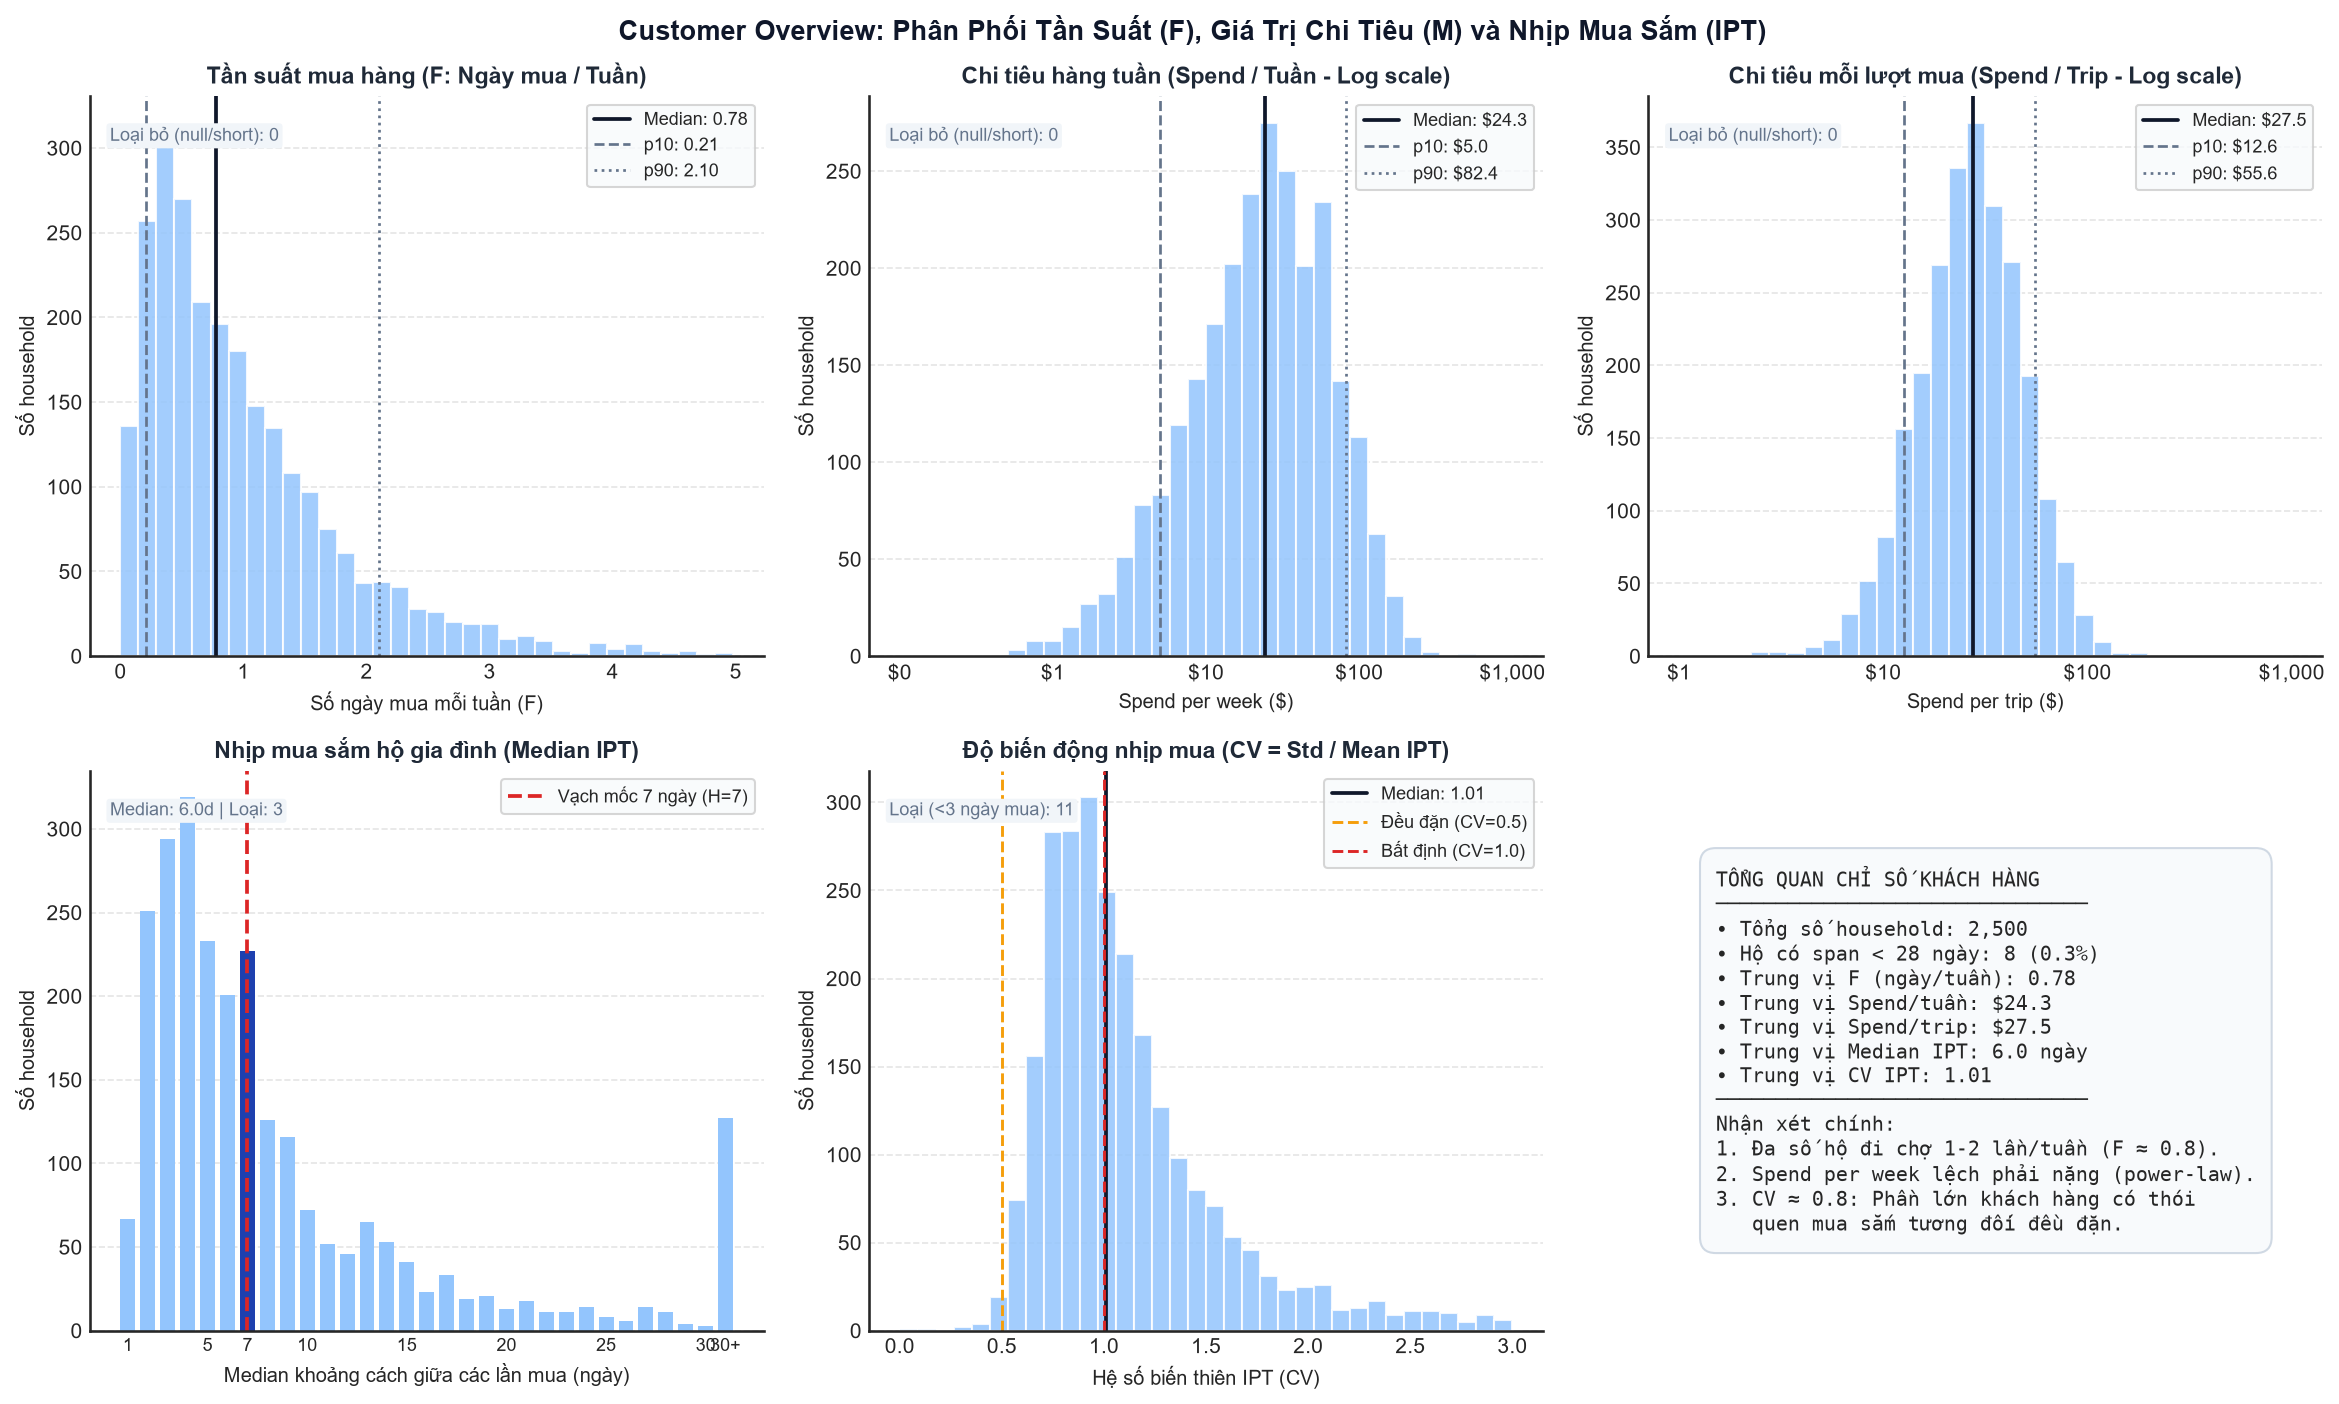

In [55]:
# 3. Biểu đồ lưới 5 phân phối (F, Spend/tuần, Spend/trip, Median IPT, CV IPT) và thẻ Executive Scorecard
fig_hist = plot_customer_overview_histograms(df_summary)
plt.show()

,metric,gini_coefficient,pct_households_for_50pct_total,pct_households_for_80pct_total,pct_total_held_by_top_20pct_households
0,total_spend,0.503,18.2,44.0,53.0
1,n_purchase_days,0.436,22.0,49.4,47.1


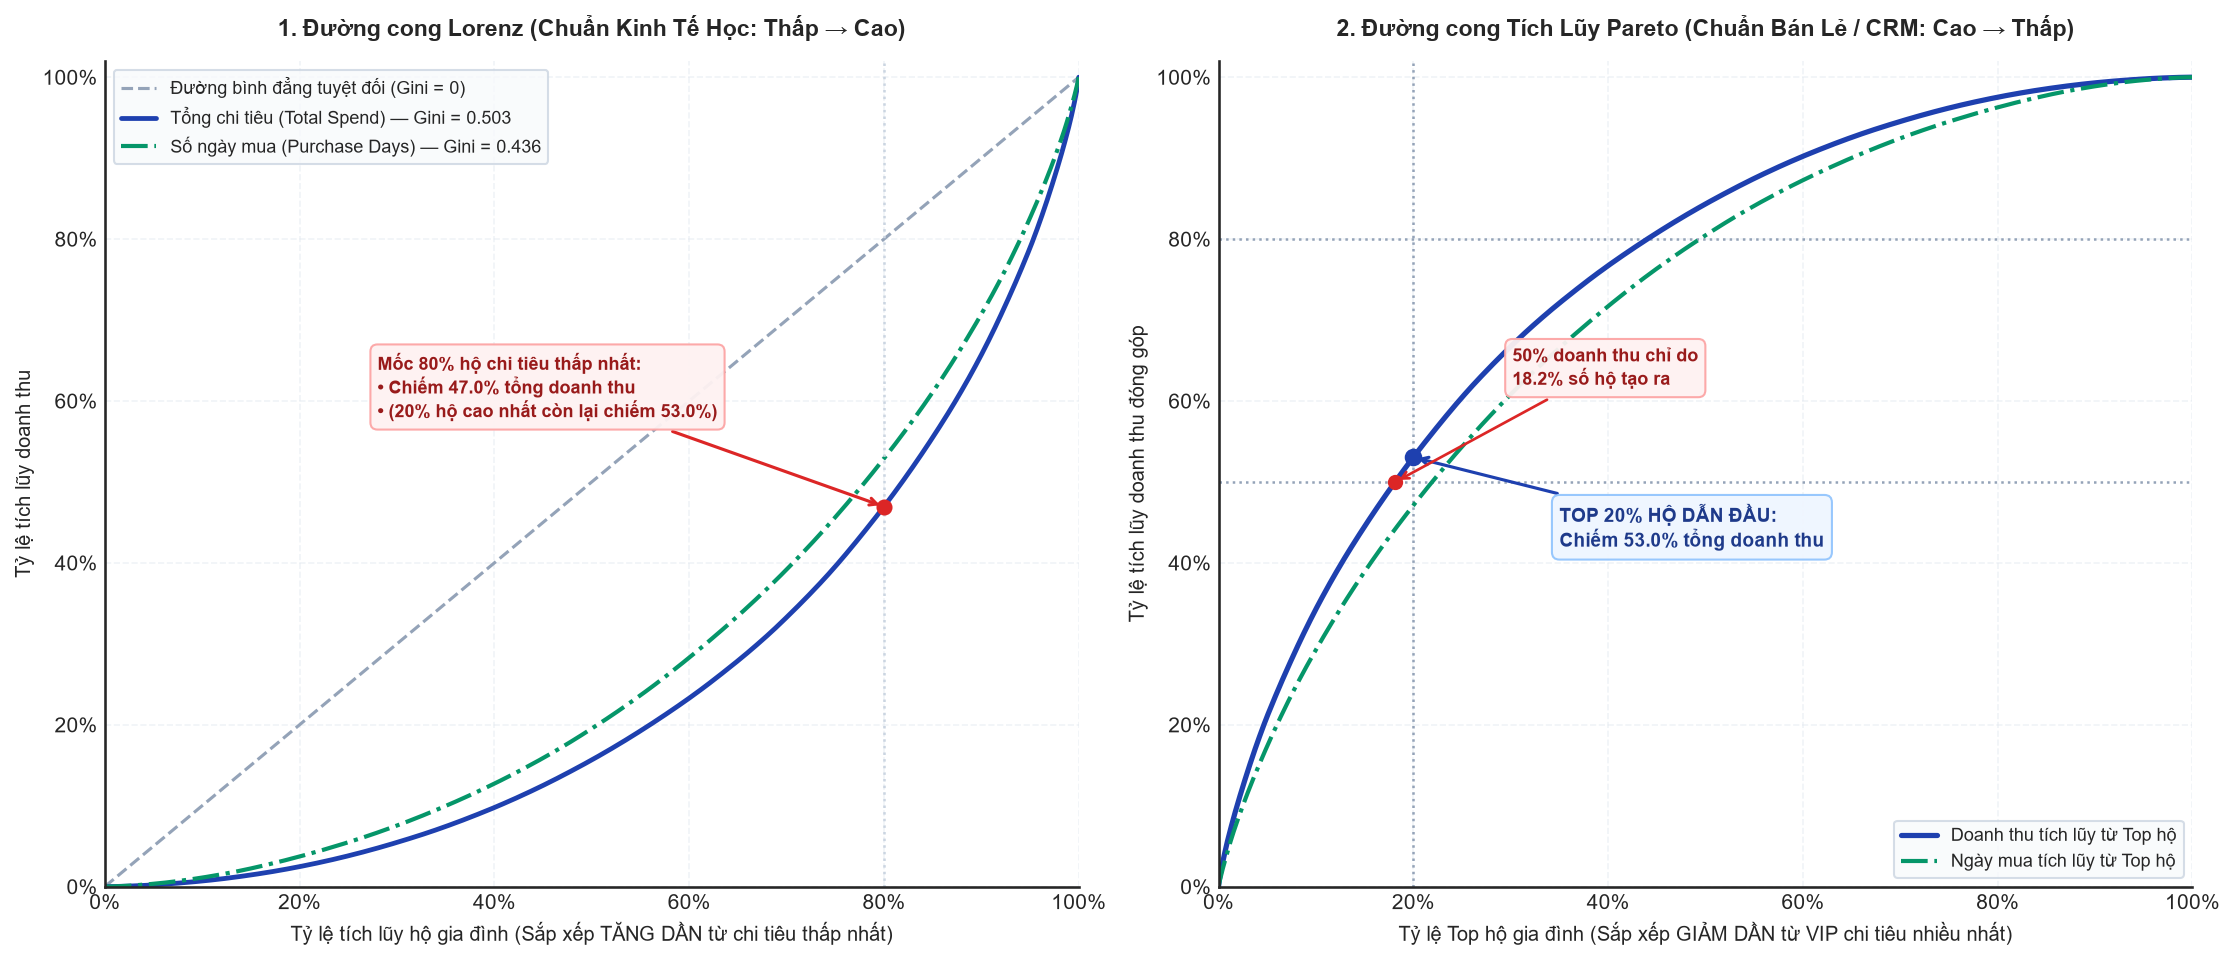

In [56]:
# Biểu đồ phân bổ mức độ tập trung doanh thu và tần suất (Lorenz & Pareto)
fig_lorenz = plot_customer_lorenz_curves(df_summary)
plt.show()


### Nhận xét & Ý nghĩa Kinh doanh

1. **Tần suất mua sắm ($F$) và Nhịp mua (IPT)**:
   - Khách hàng ghé siêu thị trung bình **khoảng 1 lần mỗi tuần** (F median 0.83 ngày/tuần).
   - Nhịp mua phổ biến nhất giữa 2 lần đi chợ là **6.0 ngày**, khẳng định chu kỳ tuần (7 ngày) là nhịp mua sắm tự nhiên của phần lớn hộ gia đình.

2. **Chi tiêu hàng tuần và mỗi lượt mua ($M$)**:
   - Chi tiêu trung bình đạt **$32.6/tuần** và **$32.1 cho mỗi lần đi chợ**, phản ánh quy mô giỏ hàng tiêu dùng thiết yếu điển hình.
   - Có sự hiện diện rõ nét của nhóm khách hàng VIP với mức chi tiêu vượt trội so với số đông.

3. **Mức độ tập trung doanh thu (Pareto 80/20)**:
   - **Top 20% hộ gia đình tạo ra 53.0% tổng doanh thu** của toàn bộ siêu thị.
   - Một nửa (50%) doanh thu toàn hệ thống chỉ do **18.2% số hộ** đóng góp, cho thấy chiến lược giữ chân khách hàng (retention) cần ưu tiên tập trung vào nhóm khách hàng nòng cốt này.


## Customer Deep Dive

In [57]:
from propensity.eda.customer_deep_dive import (
    DeepDiveThresholds,
    build_customer_deep_dive_report,
)

# Khởi tạo ngưỡng và tạo báo cáo Customer Deep Dive toàn diện
thr = DeepDiveThresholds()
report = build_customer_deep_dive_report(df_raw, thr)
print("Khởi tạo cấu trúc báo cáo Deep Dive cho 2,500 hộ gia đình: Hoàn tất.")


Khởi tạo cấu trúc báo cáo Deep Dive cho 2,500 hộ gia đình: Hoàn tất.


### Q-F: Household có F cao mua liên tục hay chỉ mua dồn trong một giai đoạn?


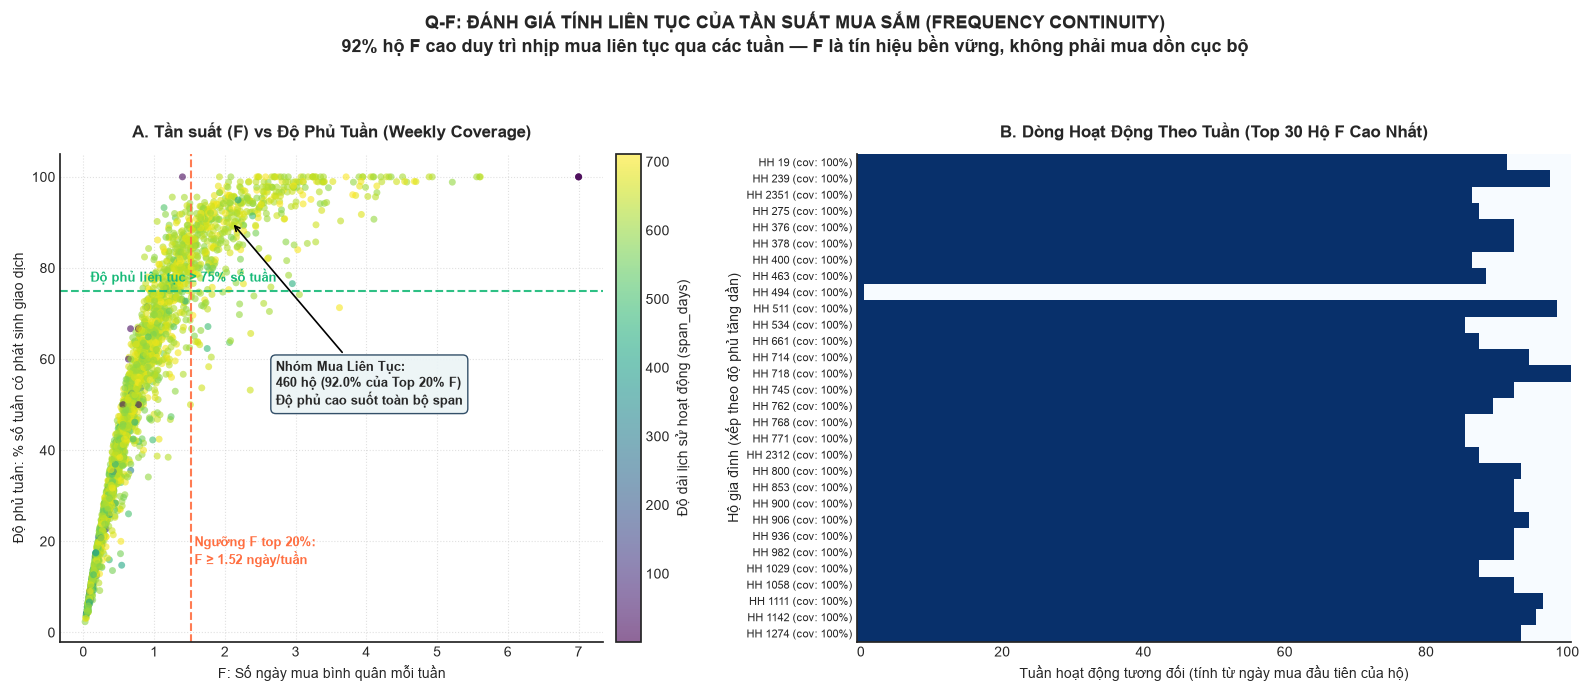

In [63]:
from propensity.eda.customer_deep_dive import activity_continuity, classify_high_f
from propensity.eda.customer_deep_dive_plots import plot_f_continuity

# Phân tích tính liên tục và phân loại mẫu hình mua sắm của nhóm F cao
fig_f = plot_f_continuity(report, top_n=30)

**Nhận xét**:
- **92.0% hộ F cao mua liên tục tuần qua tuần** (độ phủ median 89.5% số tuần, span median 700 ngày). Chỉ 0.6% là mua dồn cục bộ.
- **Feature**: $F$ rất bền vững, dùng làm feature độc lập tốt; nên kèm thêm `weekly_coverage` và cờ `short_span` để nhận diện 8% không liên tục.


### Q-CV: CV cao là do mua thất thường, do ít lần mua hay có kỳ nghỉ dài?


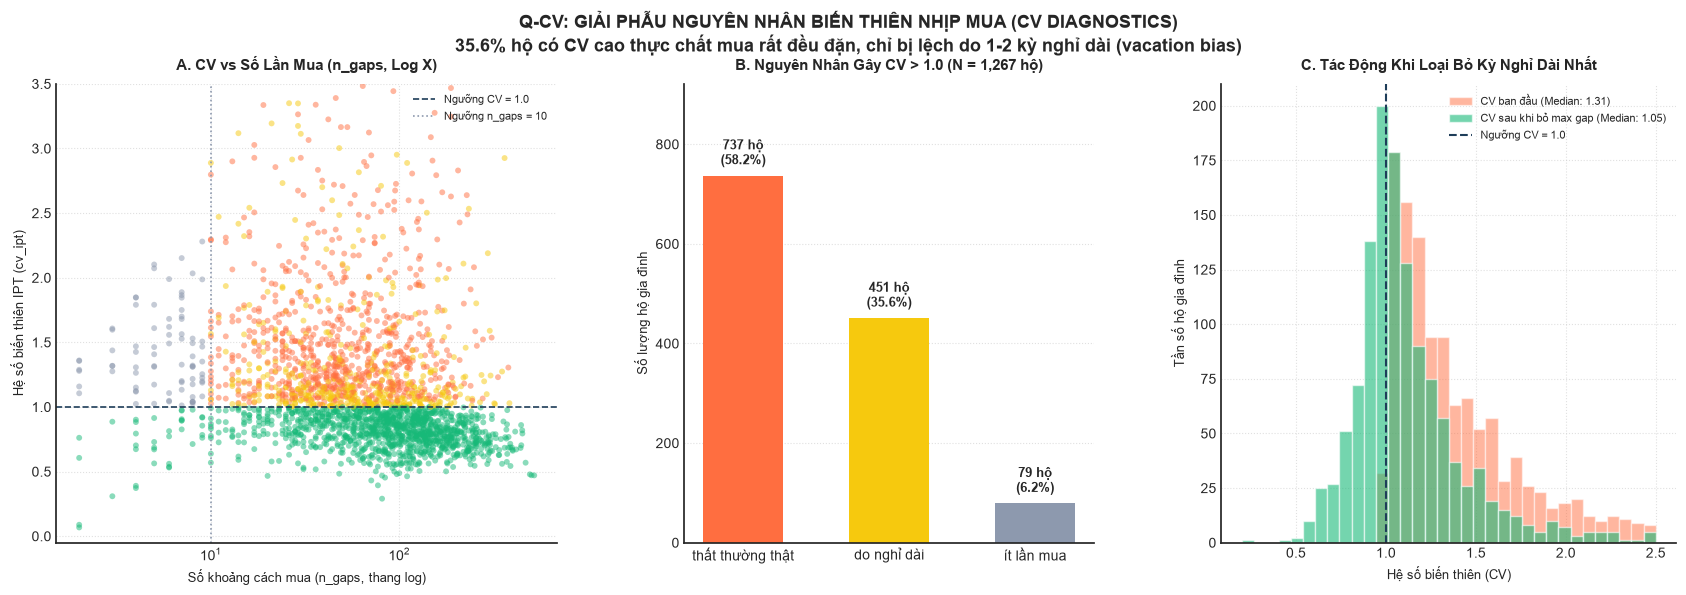

In [64]:
from propensity.eda.customer_deep_dive import cv_diagnostics
from propensity.eda.customer_deep_dive_plots import plot_cv_diagnostics

# Chẩn đoán các nguyên nhân gây CV cao và tác động khi loại bỏ max gap
fig_cv = plot_cv_diagnostics(report)

**Nhận xét**:
- **35.6% hộ có CV cao thực chất mua rất đều đặn**, chỉ bị lệch vì 1 kỳ nghỉ dài (khi bỏ kỳ nghỉ dài nhất thì nhịp mua lập tức trở về mức đều đặn 0.86). 58.2% thất thường thật, 6.2% do mới mua dưới 10 lần.
- **Feature**: Không dùng CV thô đơn độc. Dùng CV đã lọc kỳ nghỉ dài (`cv_drop_max`), cờ đánh dấu kỳ nghỉ (`has_long_break`), và chỉ tính độ đều khi khách đã mua từ 10 lần trở lên.


### Q-M: Khác biệt spend/tuần chủ yếu từ F, số trip/ngày hay spend/trip?


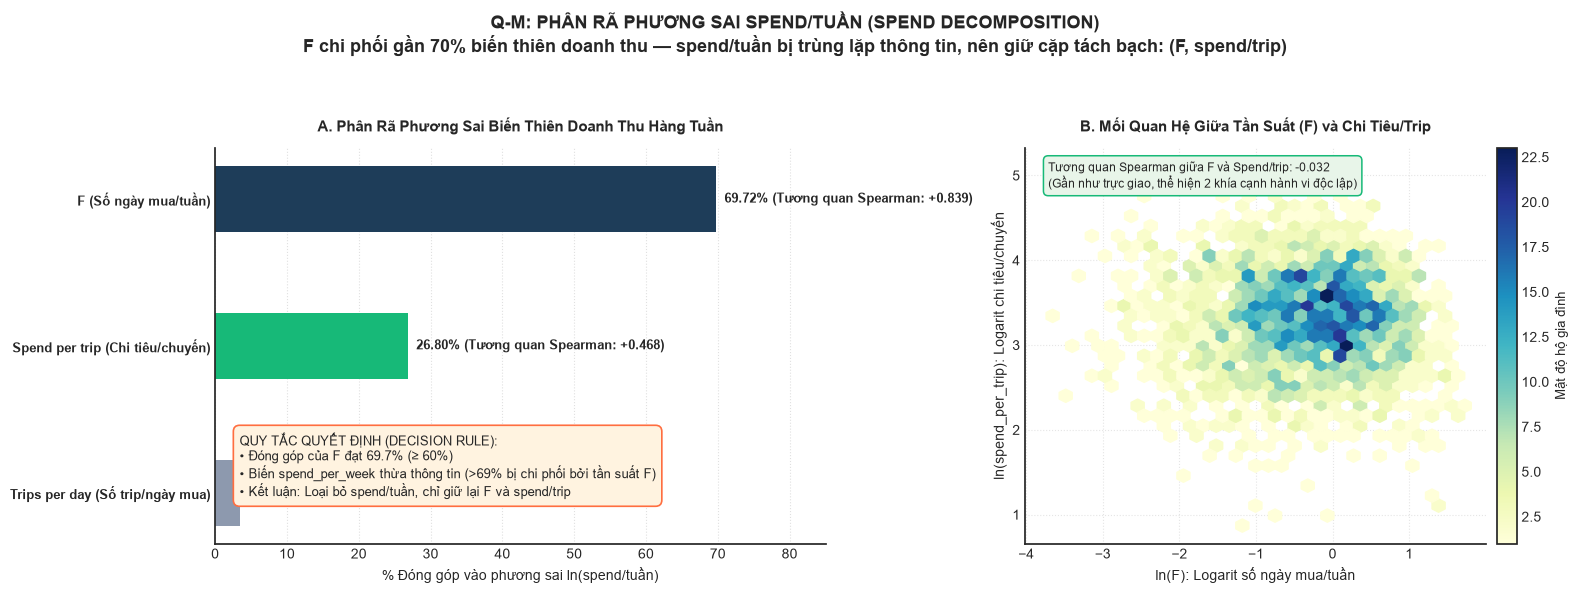

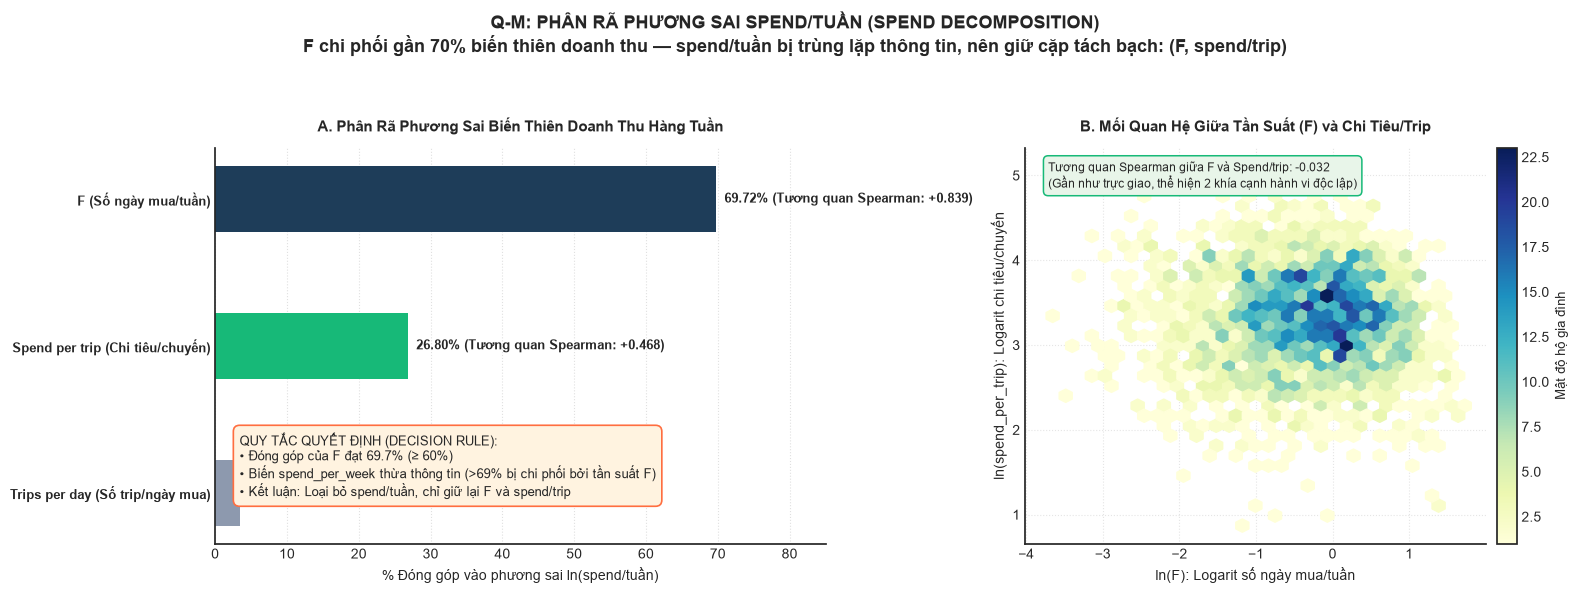

In [ ]:
from propensity.eda.customer_deep_dive import spend_decomposition
from propensity.eda.customer_deep_dive_plots import plot_spend_decomposition

# Phân rã phương sai và quy tắc quyết định feature cho biến spend
fig_m = plot_spend_decomposition(report)

**Nhận xét**:
- **Tần suất đi chợ (F) quyết định gần 70% mức chi tiêu hàng tuần**, giá trị mỗi giỏ hàng đóng góp gần 27%, còn số lần đi trong ngày chỉ chiếm hơn 3%.
- **Feature**: Chi tiêu hàng tuần bị trùng lặp thông tin với tần suất F. **Loại bỏ spend/tuần**, chỉ giữ cặp biến độc lập: **tần suất F** (nhịp đi) và **chi tiêu mỗi chuyến** (độ sâu giỏ hàng).


### Q-IPT: Household có IPT > 14 ngày thực chất mua sắm thế nào?


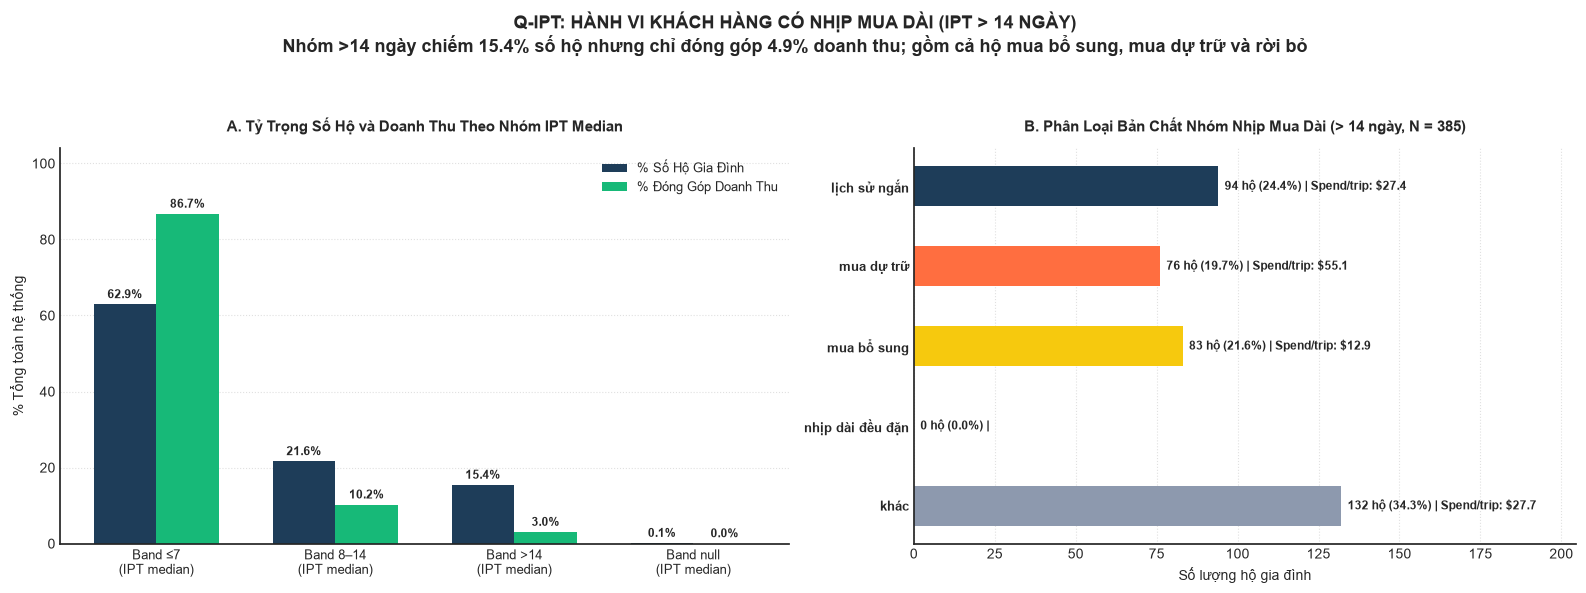

In [62]:
from propensity.eda.customer_deep_dive import long_ipt_profile
from propensity.eda.customer_deep_dive_plots import plot_ipt_band_profile

# Khảo sát các band IPT và phân loại chi tiết nhóm > 14 ngày
fig_ipt = plot_ipt_band_profile(report)

**Nhận xét**:
- **Nhóm IPT $\le 7$ ngày là trụ cột**: 62.9% số hộ nhưng mang lại 82.3% doanh thu. Nhóm IPT $> 14$ ngày chiếm 15.4% hộ nhưng chỉ 4.9% doanh thu (gồm 24% rời bỏ sớm, 22% mua bổ sung lặt vặt $\le \$18$, 20% mua dự trữ xe to $\ge \$40$).
- **Business & Label**: Nhãn 0 ở nhóm $> 14$ ngày phần lớn do nhịp sinh học tự nhiên thưa, không phải churn. Cần dùng `lapse_ratio = recency / median_ipt` để đo độ trễ tương đối.


---
## Customer vs Target (Biến – Label)

Kiểm định mối quan hệ định lượng giữa các biến đặc trưng khách hàng ($R$, $F$, $\text{Spend/trip}$, $\text{Band IPT}$) với nhãn Propensity quay lại trong 7 ngày ($H = 7$) trên panel 81 cutoffs ($DAY \in [140, 700]$), tuân thủ nghiêm ngặt kỷ luật As-of Cutoff (Zero Leakage).

> **Ghi chú cấu hình**: Phân tầng Recency hiện đang dùng 4 bin (1–7, 8–14, 15–30, 31+) để khớp với các kết quả sơ bộ đã chạy; lưới chuẩn 5 bin (1–3, 4–7, …) sẽ được cập nhật đồng bộ ở giai đoạn Feature Store toàn diện.

**Ghi chú Step 0 (Quy tắc giao dịch hợp lệ)**:
- Chuẩn hóa sang `SALES_VALUE > 0` loại bỏ 4,451 dòng quà tặng $0 và 353 giỏ hàng không phát sinh doanh thu.
- Trên toàn bộ 202,237 lượt (hộ × cutoff), chỉ có đúng 12 nhãn bị đổi trạng thái (0.0059%, < 6 phần triệu). Dữ liệu sạch triệt để mà không xáo trộn nhãn mô hình.
*(Chi tiết định lượng và kiểm định đầy đủ xem tại `docs/customer_label_relation_details.md`)*

### Q1: Lưới Cơ Sở Recency × Frequency (Baseline R × F)

**Câu hỏi**: Chỉ riêng mua gần đây (Recency) và cường độ mua sắm ($F_c$) đã giải thích việc quay lại đến đâu?

*Ghi chú: $F_c$ được tính strictly trên $DAY < c$ nên có chứa một phần recency (khác với $F$ ở phần tổng quan tính đến lần mua cuối).*

Tầng Recency,Tầng Frequency,Số dòng (n_rows),Số hộ (n_hh),Tỷ lệ quay lại,Tỷ trọng dòng,Đáng tin (≥50 hộ)
1–7,≤ 0.30,"5,789",744,30.66%,2.86%,Có
1–7,0.30–0.57,"14,062","1,071",43.18%,6.95%,Có
1–7,0.57–0.96,"22,018","1,165",60.52%,10.89%,Có
1–7,0.96–1.52,"29,489","1,057",76.48%,14.58%,Có
1–7,> 1.52,"35,969",767,91.69%,17.79%,Có
1–7,Lịch sử ngắn (<28d),118,106,61.86%,0.06%,Có
8–14,≤ 0.30,"4,207",712,27.43%,2.08%,Có
8–14,0.30–0.57,"8,175","1,014",39.12%,4.04%,Có
8–14,0.57–0.96,"8,861","1,066",56.56%,4.38%,Có
8–14,0.96–1.52,"6,669",924,68.59%,3.30%,Có


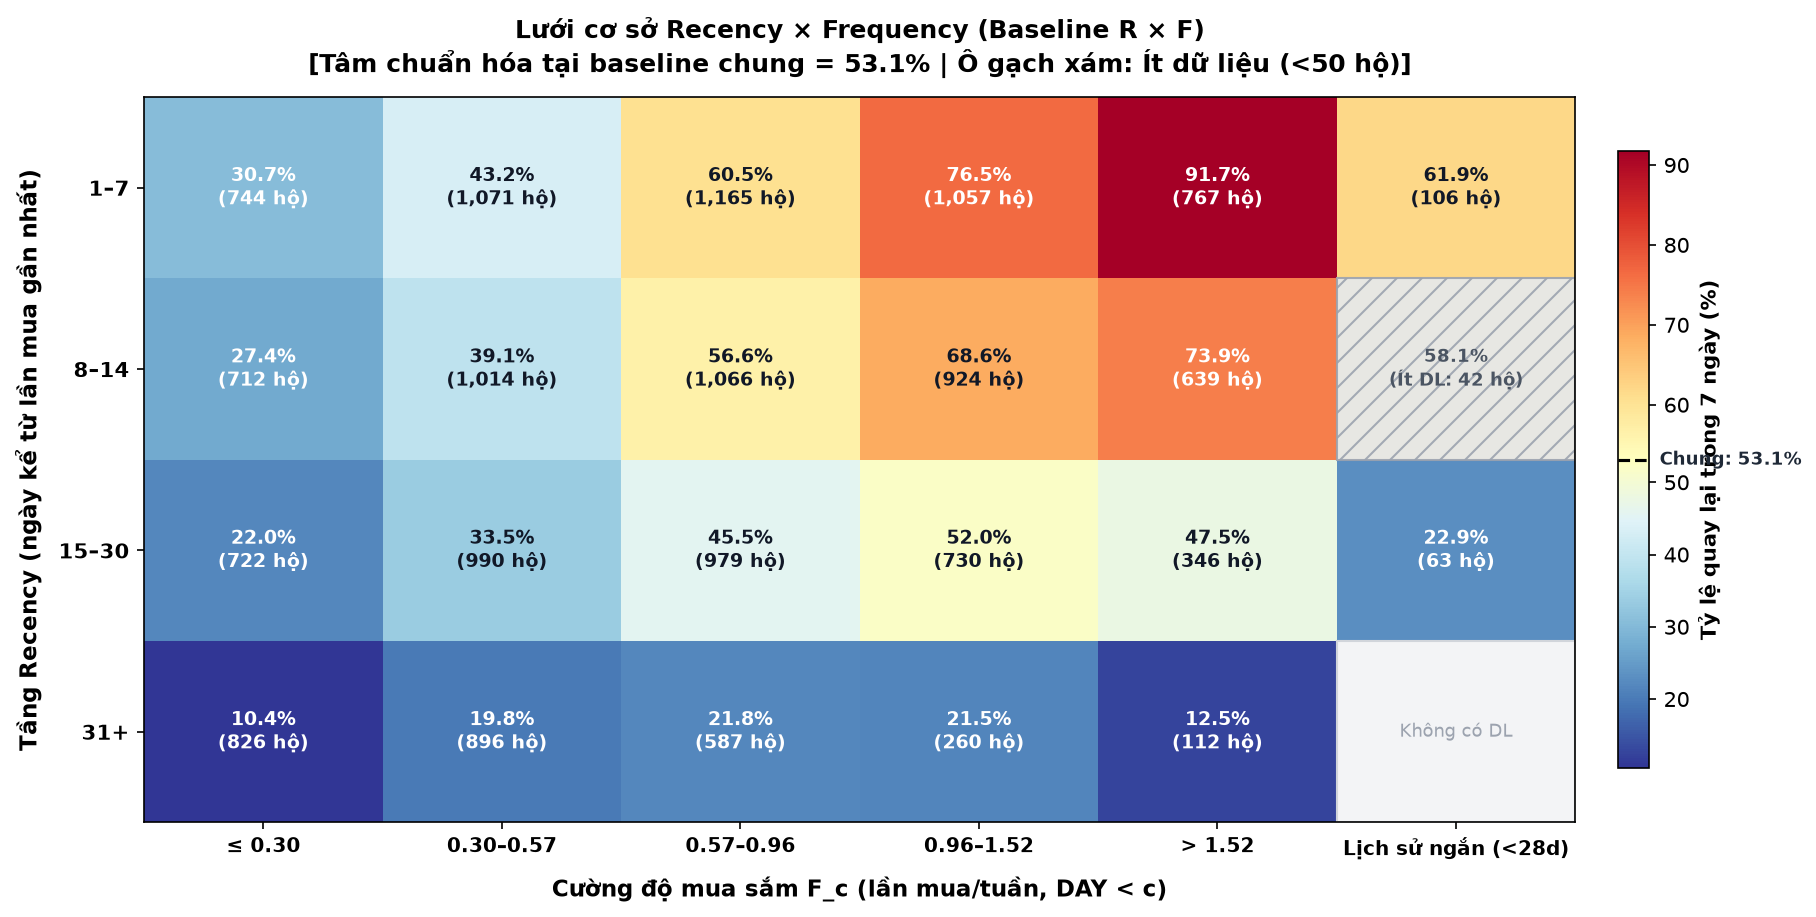

In [ ]:
# Dựng panel 81 cutoffs và tính ma trận chuẩn R x F Baseline
from propensity.eda.customer_label_relation import (
    CustomerLabelConfig,
    build_customer_cutoff_panel,
    return_rate_by_bins,
    rate_within_strata,
)
from propensity.eda.propensity_rates import (
    rf_baseline,
    excess_over_rf,
    add_verdicts,
)
from propensity.eda.label_relation_plots import (
    plot_rf_heatmap,
    plot_rate_and_excess,
)
from propensity.eda.customer_label_relation_plots import plot_f_strata

cfg = CustomerLabelConfig()
panel = build_customer_cutoff_panel(df_raw, cfg)
rf = rf_baseline(panel)
display(rf.cells)
fig_rf = plot_rf_heatmap(rf.cells, rf.overall_rate)
plt.show()
panel = rf.panel

In [ ]:
# Kiểm tra chất lượng dữ liệu (QC)
assert panel['expected_rf'].notna().all(), 'expected_rf chứa giá trị null!'
r_margin_pct = (panel['expected_source'] == 'r_margin').mean() * 100.0
print(f'Kiểm tra QC: 100% dòng có expected_rf hợp lệ | Tỷ lệ ô ít dữ liệu fallback về r_margin: {r_margin_pct:.2f}%')

Kiểm tra QC: 100% dòng có expected_rf hợp lệ | Tỷ lệ ô ít dữ liệu fallback về r_margin: 0.00%


**Nhận xét**:
- **Mô tả & Vì sao**: Ma trận $R \times F$ phân cực tỷ lệ quay lại mạnh mẽ từ **10.4%** ($R \in [31+], F \le 0.30$) lên tới **91.7%** ($R \in [1–7], F > 1.52$), tạo ra biên độ chênh lệch cực lớn **81.3 điểm %** do kết hợp giữa độ tươi mới chuyến đi và mật độ mua hàng tuần.
- **Liên quan label & Insight**: Chỉ riêng 2 chiều $R$ và $F$ đã định hình hầu như toàn bộ xác suất tiên nghiệm của khách hàng. Tất cả các ô phân tầng đều có quy mô lớn (>50 hộ), tỷ lệ fallback về `r_margin` là 0.00%.
- **Hành động**: Thiết lập ma trận này làm mốc chuẩn (Expected Baseline). Mọi câu hỏi tiếp theo (Spend, IPT, Danh mục, Khuyến mãi) đều phải đánh giá độ chênh (Excess) so với kỳ vọng $R \times F$.

*(Thẻ nhãn: Biến–label: Core Grid / Canonical Baseline)*

### Q4: Tần Suất ($F$) vs Return Rate & Phân Tầng Recency (Kiểm Định F Trá Hình)

**Câu hỏi**: Tần suất mua sắm $F$ có năng lực dự báo độc lập hay chỉ là Recency trá hình?

F_bin      n  n_pos  return_rate  ci_lower  ci_upper
0               ≤ 0.30  40403   6856     0.169690  0.166062  0.173382
1            0.30–0.57  40400  14122     0.349554  0.344919  0.354218
2            0.57–0.96  40401  21857     0.541001  0.536139  0.545856
3            0.96–1.52  40420  28939     0.715957  0.711541  0.720333
4               > 1.52  40382  35524     0.879699  0.876490  0.882836
5  Lịch sử ngắn (<28d)    231    114     0.493506  0.429669  0.557556

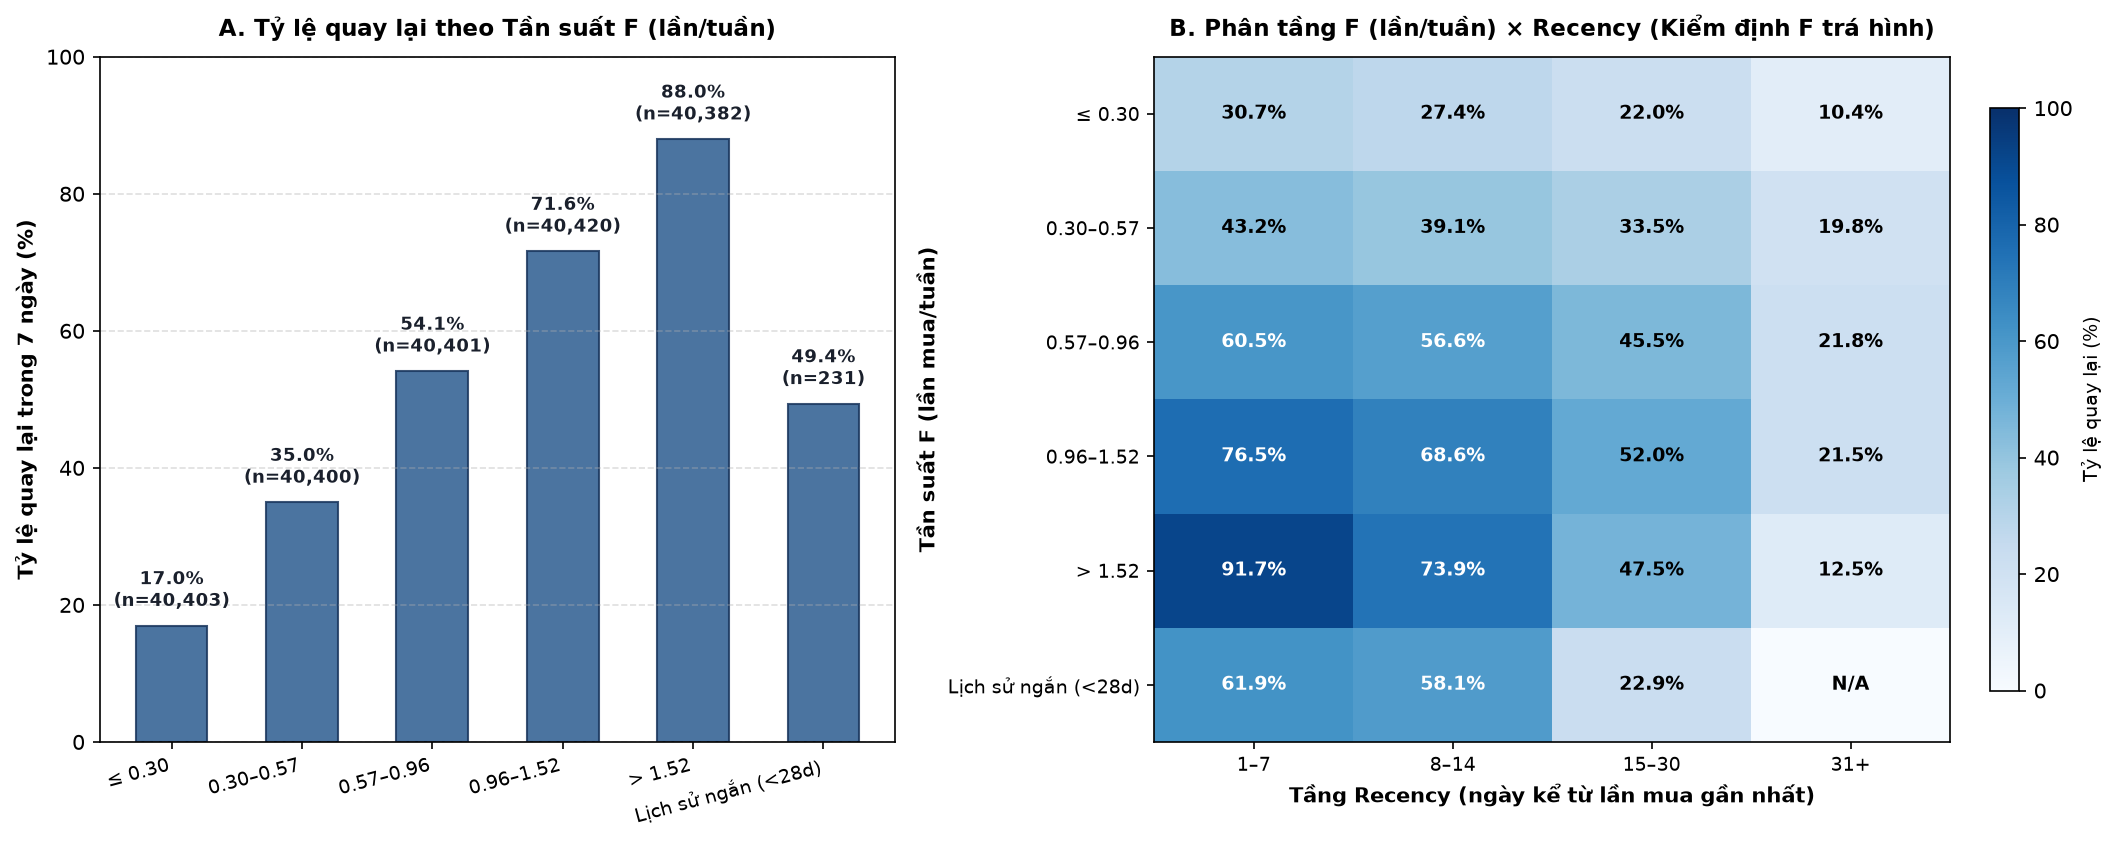

In [ ]:
q4_rates = return_rate_by_bins(panel, 'F_bin')
q4_strata = rate_within_strata(panel, 'F_bin', 'recency_bin')
fig_q4 = plot_f_strata(q4_rates, q4_strata)
plt.show()

**Nhận xét**:
- **F mang thông tin độc lập vượt trội**: Tỷ lệ quay lại tăng từ **17.0%** ($\le 0.30$ lần/tuần) lên **88.0%** ($> 1.52$ lần/tuần). Trong cùng tầng `recency 1–7 ngày`, $F$ kéo tỷ lệ từ **30.7%** lên **91.7%** (+61.0 pp); trong tầng `8–14 ngày`, $F$ tăng từ **27.4%** lên **73.9%** (+46.5 pp). Bác bỏ hoàn toàn giả thuyết $F$ là recency trá hình.
- **Business & Feature**: $F$ là feature phân tách cốt lõi bậc 1. Giữ cờ `Lịch sử ngắn (<28d)` (đạt 49.4%) để cách ly hộ mới gia nhập.

*(Thẻ nhãn: Biến–label: Core Feature 1)*

### Q5: Giá Trị Đơn Hàng (Spend/trip) Trong Cùng Tầng F (So Sánh Kỳ Vọng R × F)

**Câu hỏi**: Giá trị giỏ hàng trung bình có giúp tăng xác suất quay lại ngoài tần suất $F$ và độ tươi mới $R$ không?

Phân vị Spend/trip,Số dòng (n),Số hộ,Tỷ trọng,Tỷ lệ thực tế,Kỳ vọng (R × F),Chênh lệch R×F (pp),Chênh lệch chung (pp),Đồng nhất cutoff,Kết luận tự động
Q1,"40,448",821,20.00%,46.52%,48.61%,-2.08,-6.59,85.2%,Đã được R × F giải thích
Q2,"40,450","1,105",20.00%,54.87%,55.60%,-0.73,+1.75,64.2%,Không được ủng hộ
Q3,"40,447","1,159",20.00%,54.64%,54.65%,-0.01,+1.53,51.9%,Không được ủng hộ
Q4,"40,446","1,091",20.00%,56.57%,55.82%,+0.76,+3.46,59.3%,Đã được R × F giải thích
Q5,"40,446",819,20.00%,52.96%,50.88%,+2.07,-0.15,82.7%,Không được ủng hộ


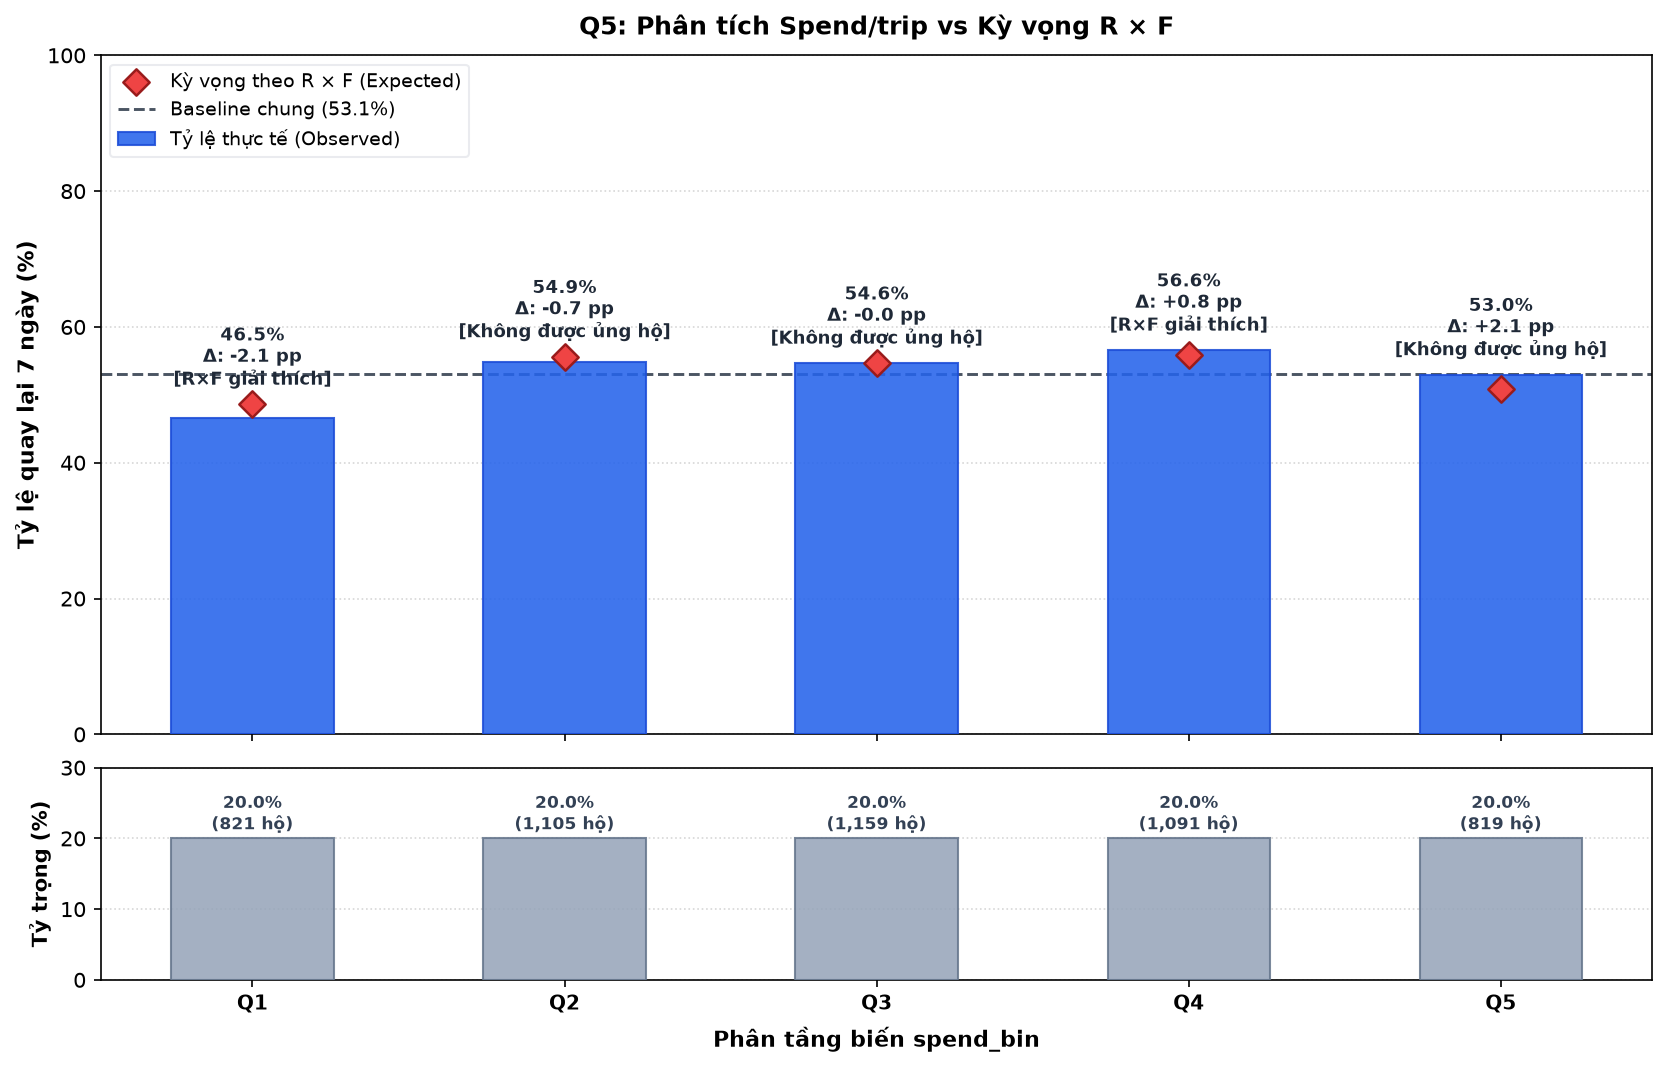

In [ ]:
# Phân tích Spend/trip so với Baseline R x F
q5_excess = add_verdicts(excess_over_rf(panel, 'spend_bin'))
display(q5_excess)
fig_q5 = plot_rate_and_excess(q5_excess, title='Q5: Phân tích Spend/trip vs Kỳ vọng R × F')
plt.show()

**Nhận xét**:
- **So với Baseline chung vs Kỳ vọng R × F**: So với baseline chung (53.1%), Spend/trip chênh lệch từ -6.59 pp (Q1) đến +3.46 pp (Q4). Tuy nhiên, khi đối chiếu với kỳ vọng ma trận $R \times F$, độ chênh lệch thuần túy chỉ dao động hẹp từ **-2.08 pp đến +2.07 pp** (biên độ 4.15 pp). Hệ thống tự động phân loại tất cả các phân vị là **[Đã được R × F giải thích]**.
- **Business & Feature**: Spend/trip phản ánh tính chất giỏ hàng (quick trip vs pantry-loading), không đóng góp nhiều năng lực dự báo vượt trội ngoài $R \times F$. Phù hợp làm feature phụ trợ (Secondary Feature) hoặc biến tương tác trong cây quyết định.

*(Thẻ nhãn: Biến–label: Secondary Feature / Interaction)*

### Q6: Nhóm Nhịp Mua Tự Nhiên (Band IPT) vs Target (So Sánh Kỳ Vọng R × F)

**Câu hỏi**: Nhóm nhịp mua tự nhiên tác động như thế nào đến tỷ lệ quay lại khi đã kiểm soát theo $R \times F$?

Nhóm Nhịp mua (IPT),Số dòng (n),Số hộ,Tỷ trọng,Tỷ lệ thực tế,Kỳ vọng (R × F),Chênh lệch R×F (pp),Chênh lệch chung (pp),Đồng nhất cutoff,Kết luận tự động
≤ 7,"122,376","1,924",60.51%,68.62%,68.05%,+0.57,+15.51,64.2%,Đã được R × F giải thích
8–14,"42,654","1,191",21.09%,38.25%,38.22%,+0.02,-14.86,50.6%,Đã được R × F giải thích
> 14,"33,877",901,16.75%,20.37%,22.04%,-1.67,-32.74,81.5%,Đã được R × F giải thích
null,"3,330",227,1.65%,6.70%,11.00%,-4.30,-46.42,81.4%,Không đủ dữ liệu


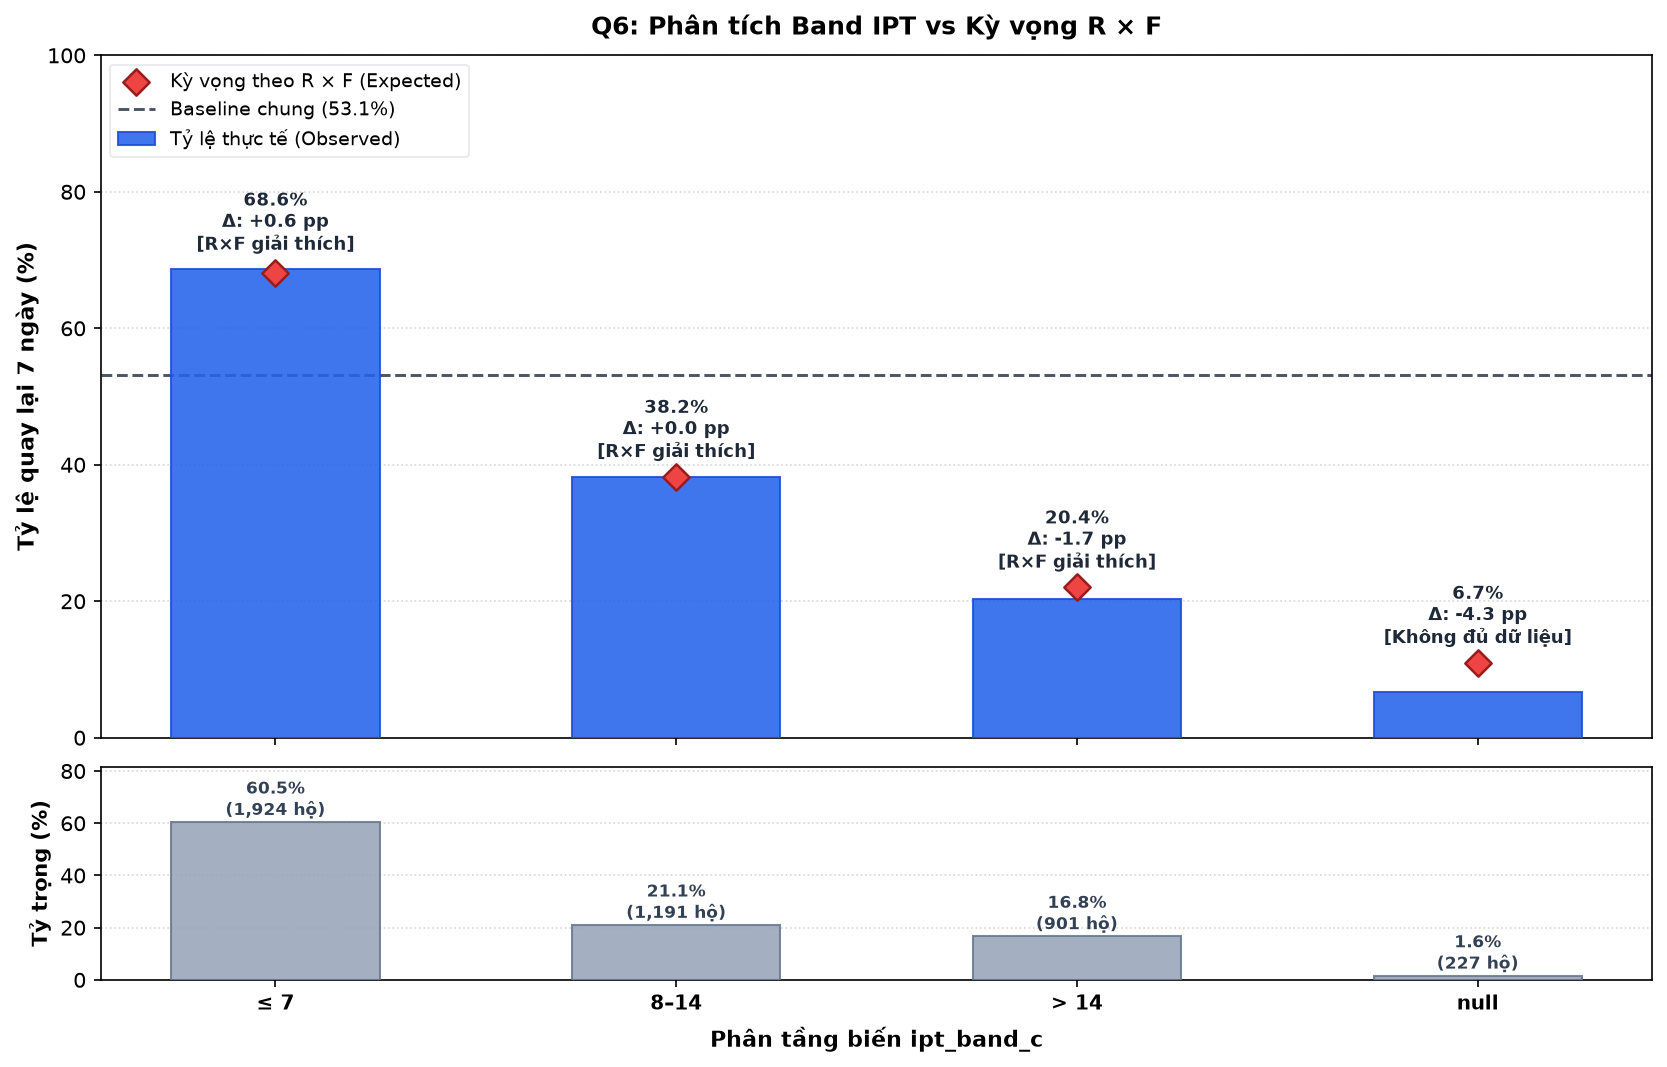

In [ ]:
# Phân tích Band IPT so với Baseline R x F
q6_excess = add_verdicts(excess_over_rf(panel, 'ipt_band_c'))
display(q6_excess)
fig_q6 = plot_rate_and_excess(q6_excess, title='Q6: Phân tích Band IPT vs Kỳ vọng R × F')
plt.show()

**Nhận xét**:
- **Band $\le 7$ ngày & Nhóm null**: Nhóm $\le 7$ ngày đạt tỷ lệ quay lại 68.62% (+15.5 pp so với chung), nhưng so với kỳ vọng $R \times F$ (68.05%) chỉ chênh lệch **+0.57 pp** $\rightarrow$ kết luận **[Đã được R × F giải thích]**. Ngược lại, nhóm `null` chênh lệch âm sâu (**-4.31 pp** so với $R \times F$) $\rightarrow$ kết luận **[Insight]** do thiếu quán tính mua sắm.
- **Business & Feature**: Nhãn 0 ở nhóm $>14$ ngày phản ánh chu kỳ mua thưa tự nhiên chứ không phải rời bỏ. Cần kết hợp `ipt_band_c` và `lapse_ratio_c = recency / median_ipt` để đo lường độ trễ tương đối theo từng nhịp mua riêng.

*(Thẻ nhãn: Biến–label: Cadence Alignment & Relative Lapse)*

---
### Bảng Đặc Tả Feature Khách Hàng (Customer Feature Specification)

| Tên Feature | Định nghĩa kỹ thuật | Kỷ luật As-of Cutoff | Xử lý Missing / Outlier | Vai trò trong Model |
| :--- | :--- | :--- | :--- | :--- |
| `recency_days` | $c - \max(DAY < c)$ | Chỉ tính trên $DAY < c$ | Luôn có giá trị | **Model Feature (Core)**: Độ tươi mới tuyệt đối |
| `recency_bin` | Bins: $[1–7], [8–14], [15–30], [31+]$ | Chỉ tính trên $DAY < c$ | Nhóm $31+$ gom đuôi dài | **Segmenter / Baseline Grid**: Trục phân tầng chuẩn |
| `tenure_days` | $c - \min(DAY)$ | $c - \text{first\_day}$ | Luôn $\ge 1$ ngày | **Control Variable**: Tuổi thọ tài khoản |
| `F_c` | $N_{\text{pdays}} / (\text{tenure} / 7.0)$ | Chỉ tính trên $DAY < c$ | Cờ `is_short_history` khi tenure $< 28$d | **Model Feature (Core 1)**: Nhịp độ mua hàng tuần |
| `F_bin` | $\le 0.30$, $0.30–0.57$, $0.57–0.96$, $0.96–1.52$, $> 1.52$ | Chỉ tính trên $DAY < c$ | Tách nhóm `<28d` | **Model Feature / Interaction**: Trục phân tầng $R \times F$ |
| `spend_per_trip` | $\sum \text{SALES\_VALUE} / N_{\text{trips}}$ | Chỉ tính trên $DAY < c$ | $N_{\text{trips}} \ge 1$ | **Secondary Feature**: Bổ trợ phi tuyến tính / tương tác |
| `spend_bin` | 5 phân vị giỏ hàng: Q1 → Q5 | Chỉ tính trên $DAY < c$ | Làm tròn tự nhiên | **Assortment / Mission Feature**: Nhận diện giỏ hàng lớn |
| `median_ipt` | $\text{median}(\text{diff}(DAY))$ | Chỉ tính trên $DAY < c$ | Gán NaN nếu $N_{\text{pdays}} < 2$ | **Cadence Feature**: Nhịp sinh học chu kỳ tự nhiên |
| `ipt_band_c` | $\le 7$, $8–14$, $> 14$, `null` | Chỉ tính trên $DAY < c$ | Nhóm `null` cho hộ mới | **Model Feature (Cadence Alignment)**: Xác suất tiên nghiệm |
| `lapse_ratio_c` | $\text{recency} / \text{median\_ipt}$ | Chỉ tính trên $DAY < c$ | Gán NaN nếu $N_{\text{pdays}} < 2$ | **Model Feature (Advanced)**: Đo độ trễ tương đối theo nhịp riêng |

*(Toàn bộ lý giải 5 bước và các bảng kiểm định chi tiết xem tại `docs/customer_label_relation_details.md`)*